# PROJET: Detection Automatique du Comportement des Etudiants avec YOLOv8
Description: Systeme complet avec equilibrage automatique des classes

## SECTION 1: INSTALLATION ET IMPORTS

In [1]:
print("Installation des dependances...")

!pip install ultralytics>=8.0.0 -q
!pip install gradio -q
!pip install opencv-python-headless -q
!pip install albumentations -q

import os
import shutil
import yaml
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
import numpy as np
from google.colab import drive, files
import zipfile
from datetime import datetime
import json
from collections import defaultdict
import random

# Imports YOLOv8
from ultralytics import YOLO
import torch

# Imports Gradio
import gradio as gr

# Imports for augmentation
import albumentations as A

print("Imports termines")
print(f"GPU disponible: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")

Installation des dependances...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Imports termines
GPU disponible: True
   GPU: Tesla T4


## SECTION 2: MONTAGE GOOGLE DRIVE

In [2]:
print("\nMontage de Google Drive...")
drive.mount('/content/drive')

# Configuration des chemins
DRIVE_PATH = '/content/drive/MyDrive/YOLO-Controle'
DATASET_PATH = f'{DRIVE_PATH}/dataset'
WORKSPACE = '/content/workspace'
os.makedirs(WORKSPACE, exist_ok=True)

print(f"Drive monte. Verification du dataset...")


Montage de Google Drive...
Mounted at /content/drive
Drive monte. Verification du dataset...


## SECTION 3: FONCTIONS UTILITAIRES

In [3]:
def convert_labels_to_indices(dataset_path):
    """Convertit les labels texte en indices numeriques et nettoie le format"""
    print("\n" + "="*80)
    print("CONVERSION ET NETTOYAGE DES LABELS")
    print("="*80)

    labels_path = Path(dataset_path) / 'labels'

    # Mapping des classes
    class_mapping = {
        'distracted': 0,
        'concentrating': 1,
        'hand_raised': 2,
        'phone': 3,
        'sleeping': 4
    }

    if not labels_path.exists():
        print("Dossier 'labels' introuvable!")
        return False

    label_files = list(labels_path.glob('*.txt'))
    converted_count = 0
    cleaned_count = 0
    already_clean = 0

    for label_file in label_files:
        try:
            with open(label_file, 'r') as f:
                lines = f.readlines()

            new_lines = []
            needs_update = False

            for line in lines:
                line = line.strip()
                if not line:
                    continue

                parts = line.split()
                if not parts or len(parts) < 5:
                    continue

                # Tenter de convertir le premier element
                try:
                    # Convertir en float puis en int pour gerer '3.0' -> 3
                    class_id = int(float(parts[0]))

                    # Verifier que c'est une classe valide (0-4)
                    if 0 <= class_id <= 4:
                        # Nettoyer les coordonnees
                        coords = [float(x) for x in parts[1:5]]
                        new_line = f"{class_id} {coords[0]:.6f} {coords[1]:.6f} {coords[2]:.6f} {coords[3]:.6f}"
                        new_lines.append(new_line)

                        # Verifier si on a modifie quelque chose
                        if new_line != line:
                            needs_update = True
                    else:
                        print(f"   Classe invalide {class_id} dans {label_file.name}")

                except ValueError:
                    # C'est probablement du texte
                    needs_update = True
                    class_name = parts[0].lower()

                    if class_name in class_mapping:
                        class_id = class_mapping[class_name]
                        coords = [float(x) for x in parts[1:5]]
                        new_line = f"{class_id} {coords[0]:.6f} {coords[1]:.6f} {coords[2]:.6f} {coords[3]:.6f}"
                        new_lines.append(new_line)
                        converted_count += 1
                    else:
                        print(f"   Classe inconnue '{class_name}' dans {label_file.name}")

            if needs_update:
                # Sauvegarder le fichier nettoye
                with open(label_file, 'w') as f:
                    f.write('\n'.join(new_lines) + '\n')
                cleaned_count += 1
            else:
                already_clean += 1

        except Exception as e:
            print(f"Erreur avec {label_file.name}: {e}")

    print(f"\nNettoyage termine:")
    print(f"   Fichiers convertis (texte->nombre): {converted_count}")
    print(f"   Fichiers nettoyes (format corrige): {cleaned_count}")
    print(f"   Fichiers deja propres: {already_clean}")

    return True

def analyze_dataset(dataset_path):
    """Analyse complete du dataset"""
    print("\n" + "="*80)
    print("ANALYSE DU DATASET")
    print("="*80)

    images_path = Path(dataset_path) / 'images'
    labels_path = Path(dataset_path) / 'labels'

    if images_path.exists():
        image_files = list(images_path.glob('*.jpg')) + list(images_path.glob('*.png')) + list(images_path.glob('*.jpeg'))
        print(f"\nNombre total d'images: {len(image_files)}")
    else:
        print("Dossier 'images' introuvable!")
        return None

    if labels_path.exists():
        label_files = list(labels_path.glob('*.txt'))
        print(f"Nombre total de labels: {len(label_files)}")
    else:
        print("Dossier 'labels' introuvable!")
        return None

    # Analyse des classes
    class_counts = {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}
    class_names = ['distracted', 'concentrating', 'hand_raised', 'phone', 'sleeping']
    total_instances = 0

    # Map files to their primary classes
    file_to_classes = defaultdict(set)

    for label_file in label_files:
        try:
            with open(label_file, 'r') as f:
                lines = f.readlines()
                for line in lines:
                    line = line.strip()
                    if not line:
                        continue
                    parts = line.split()
                    if not parts:
                        continue

                    try:
                        # Convertir float -> int pour gerer '3.0'
                        class_id = int(float(parts[0]))
                        if class_id in class_counts:
                            class_counts[class_id] += 1
                            file_to_classes[label_file.stem].add(class_id)
                            total_instances += 1
                    except (ValueError, IndexError):
                        print(f"   Ligne invalide dans {label_file.name}: {line}")
                        continue
        except Exception as e:
            print(f"Erreur avec {label_file.name}: {e}")

    print(f"\nNombre total d'instances annotees: {total_instances}")

    if total_instances == 0:
        print("ATTENTION: Aucune instance trouvee!")
        return None

    print("\nDistribution par classe:")
    print("-" * 60)

    for idx, (class_id, count) in enumerate(class_counts.items()):
        percentage = (count / total_instances * 100) if total_instances > 0 else 0
        bar = "=" * int(percentage / 2)
        print(f"{class_names[idx]:15} | {count:4d} instances | {percentage:5.1f}% | {bar}")

    # Avertissement si desequilibre
    max_count = max(class_counts.values())
    min_count = min([v for v in class_counts.values() if v > 0]) if any(class_counts.values()) else 0

    if max_count > 0 and min_count > 0:
        imbalance_ratio = max_count / min_count
        if imbalance_ratio > 5:
            print(f"\nATTENTION: Dataset tres desequilibre!")
            print(f"   Ratio max/min: {imbalance_ratio:.1f}:1")
            print("   Application de l'equilibrage automatique...")

    # Visualisation
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8']
    plt.bar(class_names, [class_counts[i] for i in range(5)], color=colors)
    plt.xlabel('Classes', fontsize=12)
    plt.ylabel("Nombre d'instances", fontsize=12)
    plt.title('Distribution des Classes', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45, ha='right')

    plt.subplot(1, 2, 2)
    plt.pie([class_counts[i] for i in range(5)], labels=class_names,
            autopct='%1.1f%%', colors=colors, startangle=90)
    plt.title('Proportion des Classes', fontsize=14, fontweight='bold')

    plt.tight_layout()
    plt.savefig(f'{WORKSPACE}/dataset_distribution_original.png', dpi=150, bbox_inches='tight')
    plt.show()

    return {
        'total_images': len(image_files),
        'total_labels': len(label_files),
        'total_instances': total_instances,
        'class_distribution': class_counts,
        'file_to_classes': file_to_classes
    }

def augment_image_and_label(image_path, label_path, output_image_path, output_label_path, augmentation_pipeline):
    """Applique des augmentations a une image et met a jour ses labels"""
    try:
        # Lire l'image
        image = cv2.imread(str(image_path))
        if image is None:
            return False
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h, w = image.shape[:2]

        # Lire les bounding boxes en format YOLO
        bboxes = []
        class_labels = []

        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    class_id = int(parts[0])
                    x_center, y_center, width, height = map(float, parts[1:5])

                    # Garder le format YOLO (x_center, y_center, width, height) normalise
                    # Albumentations attend des valeurs entre 0 et 1
                    bboxes.append([x_center, y_center, width, height])
                    class_labels.append(class_id)

        if not bboxes:
            return False

        # Appliquer l'augmentation
        transformed = augmentation_pipeline(image=image, bboxes=bboxes, class_labels=class_labels)

        augmented_image = transformed['image']
        augmented_bboxes = transformed['bboxes']
        augmented_labels = transformed['class_labels']

        if not augmented_bboxes:
            return False

        # Sauvegarder l'image augmentee
        augmented_image_bgr = cv2.cvtColor(augmented_image, cv2.COLOR_RGB2BGR)
        cv2.imwrite(str(output_image_path), augmented_image_bgr)

        # Sauvegarder les labels en format YOLO
        with open(output_label_path, 'w') as f:
            for bbox, class_id in zip(augmented_bboxes, augmented_labels):
                x_center, y_center, width, height = bbox

                # Ecrire directement au format YOLO (deja normalise)
                f.write(f"{class_id} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}\n")

        return True

    except Exception as e:
        print(f"Erreur lors de l'augmentation de {image_path.name}: {str(e)}")
        return False

def balance_dataset(dataset_path, target_ratio=0.7):
    """
    Equilibre le dataset en augmentant les classes minoritaires
    target_ratio: ratio de la classe majoritaire a atteindre (0.7 = 70% de la classe majoritaire)
    """
    print("\n" + "="*80)
    print("EQUILIBRAGE AUTOMATIQUE DU DATASET")
    print("="*80)

    images_path = Path(dataset_path) / 'images'
    labels_path = Path(dataset_path) / 'labels'

    # Analyser la distribution actuelle
    class_files = defaultdict(list)

    for label_file in labels_path.glob('*.txt'):
        with open(label_file, 'r') as f:
            classes_in_file = set()
            for line in f:
                parts = line.strip().split()
                if parts:
                    try:
                        # Convertir en float puis en int pour gerer '3.0'
                        class_id = int(float(parts[0]))
                        if 0 <= class_id <= 4:
                            classes_in_file.add(class_id)
                    except (ValueError, IndexError):
                        continue

            # Associer le fichier a ses classes
            for cls in classes_in_file:
                class_files[cls].append(label_file.stem)

    class_names = ['distracted', 'concentrating', 'hand_raised', 'phone', 'sleeping']

    print("\nDistribution actuelle:")
    for cls, files in class_files.items():
        print(f"   {class_names[cls]:15}: {len(files):4d} images")

    # Calculer le nombre cible pour chaque classe
    max_count = max(len(files) for files in class_files.values())
    target_count = int(max_count * target_ratio)

    print(f"\nNombre cible par classe: {target_count} images")

    # Pipeline d'augmentation optimise pour comportements d'etudiants
    # Augmentations realistes qui preservent le contexte comportemental
    augmentation_pipeline = A.Compose([
        # Variations d'eclairage (realiste pour differentes salles/heures)
        A.OneOf([
            A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=1.0),
            A.RandomGamma(gamma_limit=(85, 115), p=1.0),
            A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=15, val_shift_limit=10, p=1.0),
        ], p=0.8),

        # Bruit et flou (cameras de surveillance realistes)
        A.OneOf([
            A.GaussNoise(var_limit=(5.0, 25.0), p=1.0),
            A.GaussianBlur(blur_limit=(3, 5), p=1.0),
            A.ISONoise(color_shift=(0.01, 0.05), intensity=(0.1, 0.3), p=1.0),
        ], p=0.3),

        # Leger recadrage (simule differents angles de camera)
        # IMPORTANT: Pas de flip horizontal car ca inverse la scene
        A.ShiftScaleRotate(
            shift_limit=0.03,      # Leger deplacement seulement
            scale_limit=0.1,       # Leger zoom in/out
            rotate_limit=2,        # Rotation minimale (camera presque toujours droite)
            border_mode=cv2.BORDER_CONSTANT,
            p=0.4
        ),

        # Simulation de compression video (realiste pour enregistrements)
        A.ImageCompression(quality_lower=75, quality_upper=95, p=0.3),

    ], bbox_params=A.BboxParams(format='yolo', label_fields=['class_labels'], min_visibility=0.4, min_area=0.01))

    # Augmenter les classes minoritaires
    augmented_count = 0

    for cls, files in class_files.items():
        shortage = target_count - len(files)

        if shortage <= 0:
            print(f"\n{class_names[cls]}: Aucune augmentation necessaire")
            continue

        print(f"\n{class_names[cls]}: Generation de {shortage} images augmentees...")

        # Generer des augmentations
        generated = 0
        attempts = 0
        max_attempts = shortage * 3

        while generated < shortage and attempts < max_attempts:
            # Choisir une image aleatoire de cette classe
            source_file = random.choice(files)

            # Chemins source
            source_image = None
            for ext in ['.jpg', '.png', '.jpeg']:
                candidate = images_path / f'{source_file}{ext}'
                if candidate.exists():
                    source_image = candidate
                    break

            if source_image is None:
                attempts += 1
                continue

            source_label = labels_path / f'{source_file}.txt'

            if not source_label.exists():
                attempts += 1
                continue

            # Chemins de sortie
            aug_suffix = f"_aug_{generated}"
            output_image = images_path / f'{source_file}{aug_suffix}{source_image.suffix}'
            output_label = labels_path / f'{source_file}{aug_suffix}.txt'

            # Appliquer l'augmentation
            success = augment_image_and_label(
                source_image, source_label,
                output_image, output_label,
                augmentation_pipeline
            )

            if success:
                generated += 1
                augmented_count += 1
                if generated % 10 == 0:
                    print(f"   Progres: {generated}/{shortage}", end='\r')

            attempts += 1

        print(f"   Complete: {generated}/{shortage} images generees")

    print(f"\nTotal d'images augmentees: {augmented_count}")

    # Analyser la nouvelle distribution
    print("\nNouvelle distribution:")
    class_files_new = defaultdict(list)

    for label_file in labels_path.glob('*.txt'):
        with open(label_file, 'r') as f:
            classes_in_file = set()
            for line in f:
                parts = line.strip().split()
                if parts:
                    try:
                        class_id = int(float(parts[0]))
                        if 0 <= class_id <= 4:
                            classes_in_file.add(class_id)
                    except (ValueError, IndexError):
                        continue

            for cls in classes_in_file:
                class_files_new[cls].append(label_file.stem)

    for cls, files in class_files_new.items():
        print(f"   {class_names[cls]:15}: {len(files):4d} images")

    # Visualisation apres equilibrage
    plt.figure(figsize=(12, 5))

    class_counts_new = [len(class_files_new[i]) for i in range(5)]

    plt.subplot(1, 2, 1)
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8']
    plt.bar(class_names, class_counts_new, color=colors)
    plt.xlabel('Classes', fontsize=12)
    plt.ylabel("Nombre d'images", fontsize=12)
    plt.title('Distribution Apres Equilibrage', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45, ha='right')

    plt.subplot(1, 2, 2)
    plt.pie(class_counts_new, labels=class_names,
            autopct='%1.1f%%', colors=colors, startangle=90)
    plt.title('Proportion Apres Equilibrage', fontsize=14, fontweight='bold')

    plt.tight_layout()
    plt.savefig(f'{WORKSPACE}/dataset_distribution_balanced.png', dpi=150, bbox_inches='tight')
    plt.show()

    return augmented_count

def prepare_dataset_split(source_path, output_path, split_ratio=(0.7, 0.2, 0.1)):
    """
    Divise le dataset en train/val/test
    """
    print("\n" + "="*80)
    print("PREPARATION DU SPLIT TRAIN/VAL/TEST")
    print("="*80)

    random.seed(42)

    source_images = Path(source_path) / 'images'
    source_labels = Path(source_path) / 'labels'

    image_files = list(source_images.glob('*.jpg')) + list(source_images.glob('*.png'))
    image_files = [f.stem for f in image_files]

    random.shuffle(image_files)

    n_total = len(image_files)
    n_train = int(n_total * split_ratio[0])
    n_val = int(n_total * split_ratio[1])

    train_files = image_files[:n_train]
    val_files = image_files[n_train:n_train+n_val]
    test_files = image_files[n_train+n_val:]

    print(f"\nSplit realise:")
    print(f"   Training:   {len(train_files)} images ({len(train_files)/n_total*100:.1f}%)")
    print(f"   Validation: {len(val_files)} images ({len(val_files)/n_total*100:.1f}%)")
    print(f"   Test:       {len(test_files)} images ({len(test_files)/n_total*100:.1f}%)")

    for split in ['train', 'val', 'test']:
        os.makedirs(f'{output_path}/images/{split}', exist_ok=True)
        os.makedirs(f'{output_path}/labels/{split}', exist_ok=True)

    def copy_files(file_list, split_name):
        for filename in file_list:
            for ext in ['.jpg', '.png', '.jpeg']:
                src_img = source_images / f'{filename}{ext}'
                if src_img.exists():
                    dst_img = Path(output_path) / 'images' / split_name / f'{filename}{ext}'
                    shutil.copy(src_img, dst_img)
                    break

            src_lbl = source_labels / f'{filename}.txt'
            if src_lbl.exists():
                dst_lbl = Path(output_path) / 'labels' / split_name / f'{filename}.txt'
                shutil.copy(src_lbl, dst_lbl)

    copy_files(train_files, 'train')
    copy_files(val_files, 'val')
    copy_files(test_files, 'test')

    print("Dataset split termine!")
    return len(train_files), len(val_files), len(test_files)

## SYSTEME D'OPTIMISATION AVEC PICKLE

In [4]:
import pickle
from typing import Dict, Any, Optional

# Configuration des chemins pickle
PICKLE_DIR = f'{DRIVE_PATH}/pickle_cache'
os.makedirs(PICKLE_DIR, exist_ok=True)

class ProjectCache:
    """Gestionnaire de cache avec pickle pour optimiser les operations"""

    def __init__(self, cache_dir=PICKLE_DIR):
        self.cache_dir = Path(cache_dir)
        self.cache_dir.mkdir(parents=True, exist_ok=True)

    def save(self, data: Any, filename: str) -> bool:
        """Sauvegarde des donnees avec pickle"""
        try:
            filepath = self.cache_dir / f"{filename}.pkl"
            with open(filepath, 'wb') as f:
                pickle.dump(data, f, protocol=pickle.HIGHEST_PROTOCOL)
            print(f"Cache sauvegarde: {filename}")
            return True
        except Exception as e:
            print(f"Erreur sauvegarde cache {filename}: {e}")
            return False

    def load(self, filename: str) -> Optional[Any]:
        """Charge des donnees depuis pickle"""
        try:
            filepath = self.cache_dir / f"{filename}.pkl"
            if filepath.exists():
                with open(filepath, 'rb') as f:
                    data = pickle.load(f)
                print(f"Cache charge: {filename}")
                return data
            return None
        except Exception as e:
            print(f"Erreur chargement cache {filename}: {e}")
            return None

    def exists(self, filename: str) -> bool:
        """Verifie si un cache existe"""
        filepath = self.cache_dir / f"{filename}.pkl"
        return filepath.exists()

    def delete(self, filename: str) -> bool:
        """Supprime un cache"""
        try:
            filepath = self.cache_dir / f"{filename}.pkl"
            if filepath.exists():
                filepath.unlink()
                print(f"Cache supprime: {filename}")
                return True
            return False
        except Exception as e:
            print(f"Erreur suppression cache {filename}: {e}")
            return False

    def clear_all(self) -> int:
        """Supprime tous les caches"""
        count = 0
        for pkl_file in self.cache_dir.glob("*.pkl"):
            try:
                pkl_file.unlink()
                count += 1
            except Exception as e:
                print(f"Erreur suppression {pkl_file.name}: {e}")
        print(f"Total caches supprimes: {count}")
        return count

    def list_caches(self) -> list:
        """Liste tous les caches disponibles"""
        caches = []
        for pkl_file in self.cache_dir.glob("*.pkl"):
            size_mb = pkl_file.stat().st_size / (1024 * 1024)
            caches.append({
                'name': pkl_file.stem,
                'size_mb': round(size_mb, 2),
                'modified': datetime.fromtimestamp(pkl_file.stat().st_mtime)
            })
        return caches

# Initialiser le gestionnaire de cache
cache = ProjectCache()

def analyze_dataset_cached(dataset_path, force_refresh=False):
    """Version optimisee de analyze_dataset avec cache pickle"""

    cache_key = "dataset_analysis"

    # Tenter de charger depuis le cache
    if not force_refresh:
        cached_data = cache.load(cache_key)
        if cached_data is not None:
            print("\n" + "="*80)
            print("ANALYSE DU DATASET (depuis cache)")
            print("="*80)

            stats = cached_data['stats']
            print(f"\nNombre total d'images: {stats['total_images']}")
            print(f"Nombre total de labels: {stats['total_labels']}")
            print(f"Nombre total d'instances: {stats['total_instances']}")

            print("\nDistribution par classe:")
            print("-" * 60)

            class_names = ['distracted', 'concentrating', 'hand_raised', 'phone', 'sleeping']
            class_counts = stats['class_distribution']

            for idx, (class_id, count) in enumerate(class_counts.items()):
                percentage = (count / stats['total_instances'] * 100) if stats['total_instances'] > 0 else 0
                bar = "=" * int(percentage / 2)
                print(f"{class_names[idx]:15} | {count:4d} instances | {percentage:5.1f}% | {bar}")

            return stats

    # Sinon, analyser normalement
    print("\n" + "="*80)
    print("ANALYSE DU DATASET (calcul complet)")
    print("="*80)

    stats = analyze_dataset(dataset_path)

    # Sauvegarder dans le cache
    if stats:
        cache_data = {
            'stats': stats,
            'timestamp': datetime.now().isoformat(),
            'dataset_path': dataset_path
        }
        cache.save(cache_data, cache_key)

    return stats

def save_training_checkpoint(model, epoch, optimizer_state, metrics, checkpoint_name="checkpoint"):
    """Sauvegarde un checkpoint d'entrainement avec pickle"""
    checkpoint = {
        'epoch': epoch,
        'metrics': metrics,
        'optimizer_state': optimizer_state,
        'timestamp': datetime.now().isoformat(),
        'model_path': str(model)
    }

    cache.save(checkpoint, f"training_{checkpoint_name}")
    print(f"Checkpoint sauvegarde: epoch {epoch}")

def load_training_checkpoint(checkpoint_name="checkpoint"):
    """Charge un checkpoint d'entrainement"""
    return cache.load(f"training_{checkpoint_name}")

def save_augmentation_config(augmentation_params, class_files_before, class_files_after):
    """Sauvegarde la configuration d'augmentation"""
    aug_data = {
        'params': augmentation_params,
        'before': class_files_before,
        'after': class_files_after,
        'timestamp': datetime.now().isoformat()
    }

    cache.save(aug_data, "augmentation_config")
    print("Configuration d'augmentation sauvegardee")

def load_augmentation_config():
    """Charge la configuration d'augmentation"""
    return cache.load("augmentation_config")

def save_dataset_split_info(train_files, val_files, test_files, split_ratio):
    """Sauvegarde les informations du split dataset"""
    split_data = {
        'train_files': train_files,
        'val_files': val_files,
        'test_files': test_files,
        'split_ratio': split_ratio,
        'timestamp': datetime.now().isoformat()
    }

    cache.save(split_data, "dataset_split")
    print("Informations du split sauvegardees")

def load_dataset_split_info():
    """Charge les informations du split dataset"""
    return cache.load("dataset_split")

def save_training_results(val_results, test_results, training_config):
    """Sauvegarde les resultats d'entrainement"""
    results_data = {
        'validation': {
            'mAP50': float(val_results.box.map50),
            'mAP50-95': float(val_results.box.map),
            'precision': float(val_results.box.mp),
            'recall': float(val_results.box.mr)
        },
        'test': {
            'mAP50': float(test_results.box.map50),
            'mAP50-95': float(test_results.box.map),
            'precision': float(test_results.box.mp),
            'recall': float(test_results.box.mr)
        },
        'config': training_config,
        'timestamp': datetime.now().isoformat()
    }

    cache.save(results_data, "training_results")
    print("Resultats d'entrainement sauvegardes")

def load_training_results():
    """Charge les resultats d'entrainement"""
    return cache.load("training_results")

def save_class_distribution_history(distribution_data, stage="original"):
    """Sauvegarde l'historique de distribution des classes"""
    history_key = f"class_distribution_{stage}"

    history_data = {
        'distribution': distribution_data,
        'stage': stage,
        'timestamp': datetime.now().isoformat()
    }

    cache.save(history_data, history_key)

def load_class_distribution_history(stage="original"):
    """Charge l'historique de distribution"""
    return cache.load(f"class_distribution_{stage}")

def prepare_dataset_split_cached(source_path, output_path, split_ratio=(0.7, 0.2, 0.1), force_refresh=False):
    """Version optimisee avec cache du split dataset"""

    cache_key = "dataset_split"

    # Verifier si le split existe deja
    if not force_refresh:
        split_info = cache.load(cache_key)

        if split_info is not None:
            # Verifier si les fichiers existent toujours
            train_path = Path(output_path) / 'images' / 'train'
            val_path = Path(output_path) / 'images' / 'val'
            test_path = Path(output_path) / 'images' / 'test'

            if train_path.exists() and val_path.exists() and test_path.exists():
                print("\n" + "="*80)
                print("SPLIT DATASET (depuis cache)")
                print("="*80)

                n_train = len(split_info['train_files'])
                n_val = len(split_info['val_files'])
                n_test = len(split_info['test_files'])
                n_total = n_train + n_val + n_test

                print(f"\nSplit existant:")
                print(f"   Training:   {n_train} images ({n_train/n_total*100:.1f}%)")
                print(f"   Validation: {n_val} images ({n_val/n_total*100:.1f}%)")
                print(f"   Test:       {n_test} images ({n_test/n_total*100:.1f}%)")

                return n_train, n_val, n_test

    # Sinon, creer le split normalement
    train_size, val_size, test_size = prepare_dataset_split(source_path, output_path, split_ratio)

    return train_size, val_size, test_size

def export_all_caches_to_drive():
    """Export tous les caches vers Drive pour backup"""
    backup_dir = f'{DRIVE_PATH}/pickle_backup_{datetime.now().strftime("%Y%m%d_%H%M%S")}'
    os.makedirs(backup_dir, exist_ok=True)

    exported = 0
    for pkl_file in Path(PICKLE_DIR).glob("*.pkl"):
        try:
            shutil.copy(pkl_file, backup_dir)
            exported += 1
        except Exception as e:
            print(f"Erreur export {pkl_file.name}: {e}")

    print(f"\nBackup complete: {exported} fichiers exportes vers {backup_dir}")
    return backup_dir

def generate_cache_report():
    """Genere un rapport sur l'utilisation du cache"""
    print("\n" + "="*80)
    print("RAPPORT D'UTILISATION DU CACHE")
    print("="*80)

    caches = cache.list_caches()

    if not caches:
        print("\nAucun cache disponible")
        return

    total_size = sum(c['size_mb'] for c in caches)

    print(f"\nNombre de caches: {len(caches)}")
    print(f"Taille totale: {total_size:.2f} MB")
    print("\nDetails:")
    print("-" * 80)

    for c in sorted(caches, key=lambda x: x['modified'], reverse=True):
        print(f"{c['name']:30} | {c['size_mb']:8.2f} MB | {c['modified'].strftime('%Y-%m-%d %H:%M:%S')}")

# ============================================================================
# FONCTIONS UTILITAIRES POUR GESTION INTELLIGENTE DU CACHE
# ============================================================================

def smart_cache_manager(force_refresh_all=False):
    """Gestionnaire intelligent du cache"""
    print("\n" + "="*80)
    print("GESTIONNAIRE INTELLIGENT DU CACHE")
    print("="*80)

    if force_refresh_all:
        print("\nSuppression de tous les caches...")
        cache.clear_all()
        print("Mode: Calcul complet de toutes les operations")
        return

    # Verifier l'age des caches
    caches = cache.list_caches()

    for c in caches:
        age_hours = (datetime.now() - c['modified']).total_seconds() / 3600

        if age_hours > 24:
            print(f"\nCache obsolete detecte: {c['name']} (age: {age_hours:.1f}h)")
            response = input(f"Supprimer ce cache? (o/n): ")
            if response.lower() == 'o':
                cache.delete(c['name'])

    print("\nGestion du cache terminee")

def initialize_project_with_cache():
    """Initialise le projet avec gestion intelligente du cache"""
    print("\n" + "="*80)
    print("INITIALISATION DU PROJET AVEC CACHE")
    print("="*80)

    # Verifier si un cache complet existe
    has_dataset_cache = cache.exists("dataset_analysis")
    has_split_cache = cache.exists("dataset_split")
    has_training_cache = cache.exists("training_results")

    print(f"\nCache disponibles:")
    print(f"   Analyse dataset: {'OUI' if has_dataset_cache else 'NON'}")
    print(f"   Split dataset: {'OUI' if has_split_cache else 'NON'}")
    print(f"   Resultats entrainement: {'OUI' if has_training_cache else 'NON'}")

    if has_dataset_cache and has_split_cache:
        print("\nCaches detectes - Le traitement sera accelere!")
        return True
    else:
        print("\nPremier lancement ou caches incomplets - Calcul complet necessaire")
        return False

# ============================================================================
# INTEGRATION DANS LE WORKFLOW PRINCIPAL
# ============================================================================

def optimized_workflow():
    """Workflow optimise utilisant le cache pickle"""

    # 1. Initialisation
    has_cache = initialize_project_with_cache()

    # 2. Conversion des labels (toujours necessaire)
    convert_labels_to_indices(DATASET_PATH)

    # 3. Analyse du dataset (avec cache)
    dataset_stats = analyze_dataset_cached(DATASET_PATH, force_refresh=not has_cache)

    if dataset_stats:
        # Sauvegarder la distribution originale
        save_class_distribution_history(dataset_stats['class_distribution'], stage="original")

    # 4. Equilibrage (si necessaire)
    if dataset_stats:
        # Verifier si deja equilibre
        aug_config = load_augmentation_config()

        if aug_config is None or not has_cache:
            print("\nEquilibrage du dataset...")
            augmented_count = balance_dataset(DATASET_PATH, target_ratio=0.55)

            # Sauvegarder la config d'augmentation
            dataset_stats_after = analyze_dataset(DATASET_PATH)
            save_augmentation_config(
                {'target_ratio': 0.55, 'augmented_count': augmented_count},
                dataset_stats['class_distribution'],
                dataset_stats_after['class_distribution']
            )
            save_class_distribution_history(dataset_stats_after['class_distribution'], stage="balanced")
        else:
            print("\nDataset deja equilibre (depuis cache)")
            augmented_count = aug_config['params']['augmented_count']

    # 5. Split du dataset (avec cache)
    PREPARED_DATASET = f'{WORKSPACE}/dataset_split'
    train_size, val_size, test_size = prepare_dataset_split_cached(
        DATASET_PATH,
        PREPARED_DATASET,
        force_refresh=not has_cache
    )

    # Generer un rapport
    generate_cache_report()

    return PREPARED_DATASET, train_size, val_size, test_size


## SECTION 4: EXECUTION


CONVERSION ET NETTOYAGE DES LABELS

Nettoyage termine:
   Fichiers convertis (texte->nombre): 0
   Fichiers nettoyes (format corrige): 132
   Fichiers deja propres: 589

ANALYSE DU DATASET

Nombre total d'images: 725
Nombre total de labels: 721
   Ligne invalide dans classes.txt: distracted
   Ligne invalide dans classes.txt: concentrating
   Ligne invalide dans classes.txt: hand_raised
   Ligne invalide dans classes.txt: phone
   Ligne invalide dans classes.txt: sleeping

Nombre total d'instances annotees: 7359

Distribution par classe:
------------------------------------------------------------
distracted      | 1132 instances |  15.4% | =======
concentrating   | 4194 instances |  57.0% | ============================
hand_raised     |  674 instances |   9.2% | ====
phone           |  806 instances |  11.0% | =====
sleeping        |  553 instances |   7.5% | ===

ATTENTION: Dataset tres desequilibre!
   Ratio max/min: 7.6:1
   Application de l'equilibrage automatique...


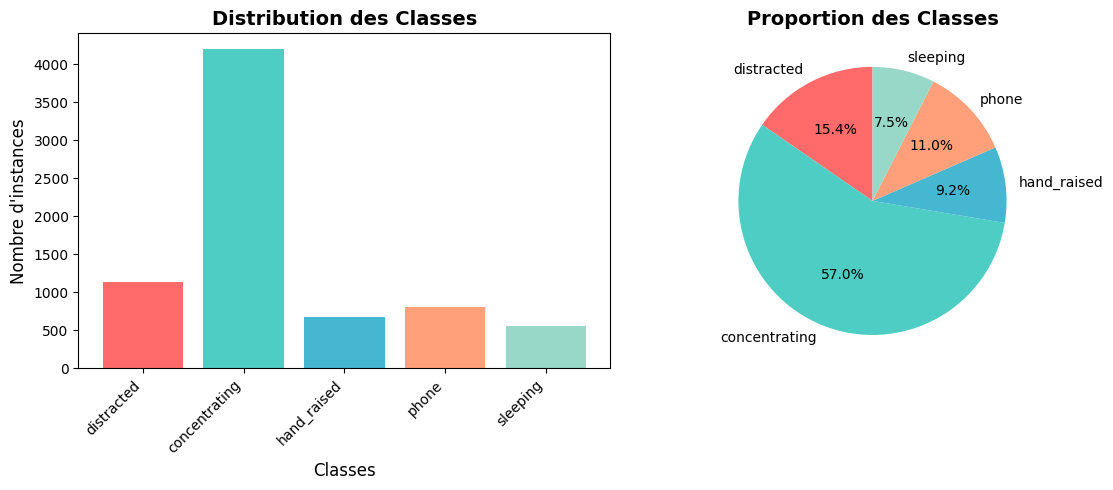


EQUILIBRAGE AUTOMATIQUE DU DATASET

Distribution actuelle:
   concentrating  :  718 images
   hand_raised    :  353 images
   distracted     :  507 images
   phone          :  358 images
   sleeping       :  360 images

Nombre cible par classe: 394 images

concentrating: Aucune augmentation necessaire

hand_raised: Generation de 41 images augmentees...


/tmp/ipykernel_569/1416530108.py:317: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 25.0), p=1.0),
/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_569/1416530108.py:333: UserWarning: Argument(s) 'quality_lower, quality_upper' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=75, quality_upper=95, p=0.3),


   Complete: 41/41 images generees

distracted: Aucune augmentation necessaire

phone: Generation de 36 images augmentees...
Erreur lors de l'augmentation de image291_aug_29.jpg: Expected x_min for bbox [-4.9919e-07     0.51128     0.15711     0.86621           1] to be in the range [0.0, 1.0], got -4.991888999938965e-07.
Erreur lors de l'augmentation de image425_aug_32.jpg: Expected x_min for bbox [-5.0291e-07     0.52879    0.093536      0.8693           1] to be in the range [0.0, 1.0], got -5.029141902923584e-07.
   Complete: 36/36 images generees

sleeping: Generation de 34 images augmentees...
Erreur lors de l'augmentation de image109_aug_7.jpg: Expected x_min for bbox [-4.9919e-07     0.48451     0.09888      0.9151           0] to be in the range [0.0, 1.0], got -4.991888999938965e-07.
   Complete: 34/34 images generees

Total d'images augmentees: 111

Nouvelle distribution:
   concentrating  :  827 images
   hand_raised    :  426 images
   distracted     :  588 images
   phone

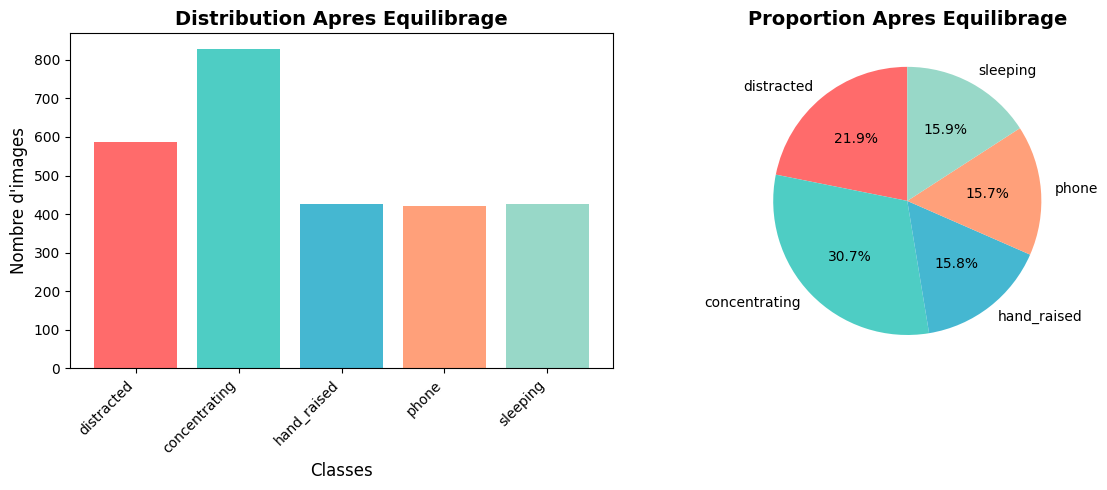


Images augmentees creees: 111

INITIALISATION DU PROJET AVEC CACHE

Cache disponibles:
   Analyse dataset: OUI
   Split dataset: OUI
   Resultats entrainement: OUI

Caches detectes - Le traitement sera accelere!

CONVERSION ET NETTOYAGE DES LABELS

Nettoyage termine:
   Fichiers convertis (texte->nombre): 0
   Fichiers nettoyes (format corrige): 111
   Fichiers deja propres: 719
Cache charge: dataset_analysis

ANALYSE DU DATASET (depuis cache)

Nombre total d'images: 593
Nombre total de labels: 589
Nombre total d'instances: 5982

Distribution par classe:
------------------------------------------------------------
distracted      |  894 instances |  14.9% | =======
concentrating   | 3507 instances |  58.6% | =============================
hand_raised     |  518 instances |   8.7% | ====
phone           |  624 instances |  10.4% | =====
sleeping        |  439 instances |   7.3% | ===
Cache sauvegarde: class_distribution_original
Cache charge: augmentation_config

Dataset deja equilibre 

In [5]:
# Convertir les labels
convert_labels_to_indices(DATASET_PATH)

# Analyser le dataset
dataset_stats = analyze_dataset(DATASET_PATH)

# Equilibrer le dataset
if dataset_stats:
    # IMPORTANT: Pour un dataset manuellement annote de haute qualite,
    # un ratio plus faible (0.5-0.6) est preferable a 0.7
    # Cela evite de surcharger avec des donnees synthetiques
    augmented_count = balance_dataset(DATASET_PATH, target_ratio=0.55)
    print(f"\nImages augmentees creees: {augmented_count}")

# Preparer le split
PREPARED_DATASET, train_size, val_size, test_size = optimized_workflow()
train_size, val_size, test_size = prepare_dataset_split(DATASET_PATH, PREPARED_DATASET)

## SECTION 5: CREATION DU FICHIER data.yaml

In [6]:
data_yaml = {
    'path': PREPARED_DATASET,
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'nc': 5,
    'names': ['distracted', 'concentrating', 'hand_raised', 'phone', 'sleeping']
}

yaml_path = f'{PREPARED_DATASET}/data.yaml'
with open(yaml_path, 'w') as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print(f"\nFichier data.yaml cree: {yaml_path}")


Fichier data.yaml cree: /content/workspace/dataset_split/data.yaml


## SECTION 6: CONFIGURATION ET ENTRAINEMENT (SKIP THIS STEP AFTER FIRST EXECUTION)

In [ ]:
print("\n" + "="*80)
print("CONFIGURATION DE L'ENTRAINEMENT")
print("="*80)

EPOCHS = 100
BATCH_SIZE = 16
IMG_SIZE = 640
MODEL_SIZE = 'yolov8m.pt'
PATIENCE = 20

config = {
    'epochs': EPOCHS,
    'batch': BATCH_SIZE,
    'imgsz': IMG_SIZE,
    'model': MODEL_SIZE,
    'patience': PATIENCE,
    'device': 0 if torch.cuda.is_available() else 'cpu'
}

print(f"\nConfiguration:")
for key, value in config.items():
    print(f"   {key:12}: {value}")

print("\n" + "="*80)
print("DEMARRAGE DE L'ENTRAINEMENT")
print("="*80)

model = YOLO(MODEL_SIZE)

results = model.train(
    data=yaml_path,
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    imgsz=IMG_SIZE,
    patience=PATIENCE,
    save=True,
    device=config['device'],
    project=f'{WORKSPACE}/runs',
    name='student_behavior_detection',
    exist_ok=True,
    pretrained=True,
    optimizer='AdamW',
    verbose=True,
    seed=42,
    deterministic=True,
    single_cls=False,
    rect=False,
    cos_lr=True,
    close_mosaic=10,
    resume=False,
    amp=True,
    fraction=1.0,
    profile=False,
    freeze=None,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    degrees=10.0,
    translate=0.1,
    scale=0.9,
    shear=0.0,
    perspective=0.0,
    flipud=0.0,
    fliplr=0.5,
    mosaic=1.0,
    mixup=0.1,
    copy_paste=0.1
)

print("\nEntrainement termine!")

best_model_path = f'{WORKSPACE}/runs/student_behavior_detection/weights/best.pt'
drive_model_path = f'{DRIVE_PATH}/best_model_balanced.pt'
shutil.copy(best_model_path, drive_model_path)
print(f"Modele sauvegarde dans Drive: {drive_model_path}")


CONFIGURATION DE L'ENTRAINEMENT

Configuration:
   epochs      : 100
   batch       : 16
   imgsz       : 640
   model       : yolov8m.pt
   patience    : 20
   device      : 0

DEMARRAGE DE L'ENTRAINEMENT
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/workspace/dataset_split/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj

## SECTION 7: EVALUATION

In [ ]:
print("\n" + "="*80)
print("EVALUATION DU MODELE")
print("="*80)

best_model = YOLO(best_model_path)

val_results = best_model.val(
    data=yaml_path,
    split='val',
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    conf=0.25,
    iou=0.6,
    max_det=300,
    plots=True
)

print("\nResultats de Validation:")
print(f"   mAP50:     {val_results.box.map50:.4f}")
print(f"   mAP50-95:  {val_results.box.map:.4f}")
print(f"   Precision: {val_results.box.mp:.4f}")
print(f"   Recall:    {val_results.box.mr:.4f}")

test_results = best_model.val(
    data=yaml_path,
    split='test',
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE
)

print("\nResultats de Test:")
print(f"   mAP50:     {test_results.box.map50:.4f}")
print(f"   mAP50-95:  {test_results.box.map:.4f}")
print(f"   Precision: {test_results.box.mp:.4f}")
print(f"   Recall:    {test_results.box.mr:.4f}")

##SAUVEGARDER LES RESULTATS AVEC PICKLE

In [ ]:
print("\n" + "="*80)
print("SAUVEGARDE DES RESULTATS AVEC PICKLE")
print("="*80)

# Sauvegarder les résultats d'entraînement
save_training_results(val_results, test_results, config)

# Sauvegarder les informations du split
save_dataset_split_info(
    train_files=list(range(train_size)),  # Vous pouvez ajuster selon vos besoins
    val_files=list(range(val_size)),
    test_files=list(range(test_size)),
    split_ratio=(0.7, 0.2, 0.1)
)

# Créer un backup de sécurité de tous les caches
backup_path = export_all_caches_to_drive()
print(f"\nBackup créé: {backup_path}")

# Afficher le rapport du cache
generate_cache_report()

## SECTION 8: VISUALISATION

In [ ]:
def visualize_predictions(model, dataset_path, split='test', n_images=6):
    """Visualise les predictions"""
    images_path = Path(dataset_path) / 'images' / split
    image_files = list(images_path.glob('*.jpg')) + list(images_path.glob('*.png'))

    selected_images = random.sample(image_files, min(n_images, len(image_files)))

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()

    for idx, img_path in enumerate(selected_images):
        results = model(str(img_path))
        img_with_boxes = results[0].plot()
        img_rgb = cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB)

        axes[idx].imshow(img_rgb)
        axes[idx].axis('off')
        axes[idx].set_title(f'Image {idx+1}', fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.savefig(f'{WORKSPACE}/predictions_visualization.png', dpi=150, bbox_inches='tight')
    plt.show()

print("\nVisualisation des predictions...")
visualize_predictions(best_model, PREPARED_DATASET, split='test', n_images=6)

## SECTION 9: INTERFACE GRADIO

In [ ]:
## SECTION 9: INTERFACE GRADIO - REAL-TIME WEBCAM DETECTION

import gradio as gr
import cv2
import numpy as np
from PIL import Image
import threading
import time
from collections import deque, defaultdict
from datetime import datetime

# Charger le meilleur modele
print("\nChargement du modele...")
best_model = None

try:
    drive_model_path = f'{DRIVE_PATH}/best_model_balanced.pt'
    if os.path.exists(drive_model_path):
        best_model = YOLO(drive_model_path)
        print(f"Modele charge depuis Drive: {drive_model_path}")
    else:
        workspace_model_path = f'{WORKSPACE}/runs/student_behavior_detection/weights/best.pt'
        if os.path.exists(workspace_model_path):
            best_model = YOLO(workspace_model_path)
            print(f"Modele charge depuis Workspace: {workspace_model_path}")
        else:
            print("ERREUR: Aucun modele trouve!")
except Exception as e:
    print(f"Erreur lors du chargement du modele: {e}")

# Configuration des couleurs
CLASS_NAMES = ['Distracted', 'Concentrating', 'Hand Raised', 'Phone', 'Sleeping']

# Tracker de performance
class PerformanceTracker:
    def __init__(self):
        self.fps_history = deque(maxlen=30)
        self.detection_history = deque(maxlen=100)
        self.start_time = time.time()
        self.frame_count = 0

    def update_fps(self, fps):
        self.fps_history.append(fps)
        self.frame_count += 1

    def update_detections(self, detections):
        class_counts = defaultdict(int)
        for det in detections:
            class_id = int(det[5])
            if 0 <= class_id < len(CLASS_NAMES):
                class_counts[CLASS_NAMES[class_id]] += 1
        self.detection_history.append(dict(class_counts))

    def get_avg_fps(self):
        return sum(self.fps_history) / len(self.fps_history) if self.fps_history else 0

    def get_stats_summary(self):
        elapsed = time.time() - self.start_time
        avg_fps = self.get_avg_fps()

        # Agreger les detections
        total_counts = defaultdict(int)
        for frame_counts in self.detection_history:
            for name, count in frame_counts.items():
                total_counts[name] += count

        summary = f"⏱ Session: {int(elapsed)}s | Frames: {self.frame_count} | FPS moyen: {avg_fps:.1f}\n\n"
        summary += "Comportements detectes:\n"
        summary += "=" * 40 + "\n"

        for name in CLASS_NAMES:
            count = total_counts.get(name, 0)
            if count > 0:
                avg_per_frame = count / len(self.detection_history) if self.detection_history else 0
                bar_length = min(int(avg_per_frame * 10), 20)
                bar = "█" * bar_length
                summary += f"{name:15} | {count:4} total | {avg_per_frame:5.2f}/frame {bar}\n"

        if not total_counts:
            summary += "  Aucune detection pour le moment\n"

        return summary

# Global tracker for webcam
webcam_tracker = PerformanceTracker()

# ============================================================================
# FONCTIONS DE TRAITEMENT IMAGE ET VIDEO
# ============================================================================

def process_image(image, conf_threshold=0.25, iou_threshold=0.45):
    """Traite une image uploadee"""
    if image is None:
        return None, "Aucune image fournie"

    if best_model is None:
        return None, "Erreur: Modele non charge"

    try:
        if isinstance(image, Image.Image):
            image = np.array(image)

        results = best_model.predict(
            image,
            conf=conf_threshold,
            iou=iou_threshold,
            verbose=False
        )

        annotated_image = results[0].plot()
        annotated_image = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

        detections = results[0].boxes.data.cpu().numpy()

        stats_text = f"Nombre de detections: {len(detections)}\n\n"

        class_counts = defaultdict(int)
        for det in detections:
            class_id = int(det[5])
            if 0 <= class_id < len(CLASS_NAMES):
                class_counts[CLASS_NAMES[class_id]] += 1

        stats_text += "Repartition:\n"
        for name in CLASS_NAMES:
            count = class_counts[name]
            if count > 0:
                stats_text += f"  {name}: {count}\n"

        return annotated_image, stats_text

    except Exception as e:
        return None, f"Erreur: {str(e)}"

def process_video(video_path, conf_threshold=0.25, iou_threshold=0.45, progress=gr.Progress()):
    """Traite une video uploadee"""
    if video_path is None:
        return None, "Aucune video fournie"

    if best_model is None:
        return None, "Erreur: Modele non charge"

    try:
        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            return None, "Impossible d'ouvrir la video"

        fps = int(cap.get(cv2.CAP_PROP_FPS))
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        output_path = f'{WORKSPACE}/output_video_{datetime.now().strftime("%Y%m%d_%H%M%S")}.mp4'
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')
        out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

        video_tracker = PerformanceTracker()
        frame_count = 0

        progress(0, desc="Traitement de la video...")

        while True:
            ret, frame = cap.read()
            if not ret:
                break

            results = best_model.predict(
                frame,
                conf=conf_threshold,
                iou=iou_threshold,
                verbose=False
            )

            annotated_frame = results[0].plot()
            detections = results[0].boxes.data.cpu().numpy()
            video_tracker.update_detections(detections)

            out.write(annotated_frame)
            frame_count += 1

            if frame_count % 10 == 0:
                progress(frame_count / total_frames, desc=f"Frame {frame_count}/{total_frames}")

        cap.release()
        out.release()

        stats_text = video_tracker.get_stats_summary()

        return output_path, stats_text

    except Exception as e:
        return None, f"Erreur: {str(e)}"

# ============================================================================
# REAL-TIME WEBCAM DETECTION - CONTINUOUS STREAMING
# ============================================================================

def process_webcam_continuous(frame, conf_threshold, iou_threshold):
    """
    Process webcam frame continuously with real-time detection.
    This function processes EVERY frame for true live streaming!
    """
    global webcam_tracker

    if frame is None:
        return None, "En attente de la webcam..."

    if best_model is None:
        return frame, "Erreur: Modele non charge"

    try:
        start_time = time.time()

        # Convert frame if needed
        if isinstance(frame, Image.Image):
            frame = np.array(frame)

        # Ensure RGB format
        if len(frame.shape) == 2:
            frame = cv2.cvtColor(frame, cv2.COLOR_GRAY2RGB)
        elif frame.shape[2] == 4:
            frame = cv2.cvtColor(frame, cv2.COLOR_RGBA2RGB)

        # Resize for faster inference while maintaining aspect ratio
        height, width = frame.shape[:2]
        max_dim = 640
        original_size = (width, height)

        if max(height, width) > max_dim:
            scale = max_dim / max(height, width)
            frame_resized = cv2.resize(frame, (int(width * scale), int(height * scale)))
        else:
            frame_resized = frame.copy()

        # Run detection
        results = best_model.predict(
            frame_resized,
            conf=conf_threshold,
            iou=iou_threshold,
            verbose=False,
            max_det=50,
            half=False
        )

        # Annotate frame with enhanced visualization
        annotated_frame = results[0].plot(
            line_width=3,
            font_size=1.0,
            labels=True,
            conf=True
        )

        # Convert BGR to RGB
        annotated_frame = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

        # Resize back to original size for display
        if annotated_frame.shape[:2] != original_size[::-1]:
            annotated_frame = cv2.resize(annotated_frame, original_size)

        # Update stats
        detections = results[0].boxes.data.cpu().numpy()
        webcam_tracker.update_detections(detections)

        # Calculate FPS
        processing_time = time.time() - start_time
        fps = 1.0 / processing_time if processing_time > 0 else 0
        webcam_tracker.update_fps(fps)

        avg_fps = webcam_tracker.get_avg_fps()

        # Add enhanced overlays to frame
        # FPS Counter (top-left)
        cv2.putText(
            annotated_frame,
            f'FPS: {avg_fps:.1f}',
            (15, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.2,
            (0, 255, 0),
            3,
            cv2.LINE_AA
        )

        # Detection count (below FPS)
        cv2.putText(
            annotated_frame,
            f'Detections: {len(detections)}',
            (15, 85),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.2,
            (0, 255, 0),
            3,
            cv2.LINE_AA
        )

        # Processing time (below detections)
        cv2.putText(
            annotated_frame,
            f'Latency: {int(processing_time * 1000)}ms',
            (15, 130),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.2,
            (0, 255, 0),
            3,
            cv2.LINE_AA
        )

        # Live indicator (top-right)
        status_text = "🔴 LIVE"
        text_size = cv2.getTextSize(status_text, cv2.FONT_HERSHEY_SIMPLEX, 1.2, 3)[0]
        cv2.putText(
            annotated_frame,
            status_text,
            (width - text_size[0] - 15, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.2,
            (0, 0, 255),
            3,
            cv2.LINE_AA
        )

        # Generate detailed stats text
        stats_text = webcam_tracker.get_stats_summary()

        return annotated_frame, stats_text

    except Exception as e:
        return frame, f"Erreur: {str(e)}"

def reset_webcam_tracker():
    """Reset the webcam tracker for new sessions"""
    global webcam_tracker
    webcam_tracker = PerformanceTracker()
    return None, "Statistiques reinitialisees"

# ============================================================================
# CONSTRUCTION DE L'INTERFACE GRADIO
# ============================================================================

print("\nConstruction de l'interface...")

with gr.Blocks(
    title="Detection Comportement Etudiants - Real-Time",
    theme=gr.themes.Soft(
        primary_hue="green",
        secondary_hue="gray",
    ),
    css="""
        .gradio-container {
            max-width: 1600px !important;
        }
        #webcam-container {
            border: 3px solid #00ff00;
            border-radius: 10px;
            padding: 10px;
            background: linear-gradient(135deg, #1a1a1a 0%, #2d2d2d 100%);
        }
        #stats-container {
            border: 2px solid #00ff00;
            border-radius: 8px;
            padding: 15px;
            background: rgba(0, 0, 0, 0.8);
            font-family: 'Courier New', monospace;
        }
    """
) as demo:

    gr.Markdown(
        """
        # Systeme de Detection Automatique du Comportement des Etudiants
        ### 🔴 DETECTION EN TEMPS REEL - Mode Streaming Continu

        **Classes detectees:** Distracted • Concentrating • Hand Raised • Phone • Sleeping
        """
    )

    with gr.Tabs():

        # TAB 1: DETECTION SUR IMAGE
        with gr.Tab("Detection sur Image"):
            gr.Markdown("### Analysez une image pour detecter les comportements")

            with gr.Row():
                with gr.Column():
                    image_input = gr.Image(type="numpy", label="Image d'entree")

                    with gr.Row():
                        img_conf = gr.Slider(
                            minimum=0.1,
                            maximum=0.9,
                            value=0.25,
                            step=0.05,
                            label="Seuil de confiance"
                        )
                        img_iou = gr.Slider(
                            minimum=0.1,
                            maximum=0.9,
                            value=0.45,
                            step=0.05,
                            label="Seuil IoU"
                        )

                    image_btn = gr.Button("Analyser l'image", variant="primary", size="lg")

                with gr.Column():
                    image_output = gr.Image(label="Resultats de detection")
                    image_stats = gr.Textbox(
                        label="Statistiques",
                        lines=10,
                        max_lines=15
                    )

            image_btn.click(
                fn=process_image,
                inputs=[image_input, img_conf, img_iou],
                outputs=[image_output, image_stats]
            )

        # TAB 2: DETECTION SUR VIDEO
        with gr.Tab("Detection sur Video"):
            gr.Markdown("### Traitez une video complete avec detection")

            with gr.Row():
                with gr.Column():
                    video_input = gr.Video(label="Video d'entree")

                    with gr.Row():
                        vid_conf = gr.Slider(
                            minimum=0.1,
                            maximum=0.9,
                            value=0.25,
                            step=0.05,
                            label="Seuil de confiance"
                        )
                        vid_iou = gr.Slider(
                            minimum=0.1,
                            maximum=0.9,
                            value=0.45,
                            step=0.05,
                            label="Seuil IoU"
                        )

                    video_btn = gr.Button("Traiter la video", variant="primary", size="lg")

                with gr.Column():
                    video_output = gr.Video(label="Video annotee")
                    video_stats = gr.Textbox(
                        label="Statistiques",
                        lines=10,
                        max_lines=15
                    )

            video_btn.click(
                fn=process_video,
                inputs=[video_input, vid_conf, vid_iou],
                outputs=[video_output, video_stats]
            )

        # TAB 3: DETECTION EN DIRECT (WEBCAM) - CONTINUOUS STREAMING
        with gr.Tab("Detection en Direct (Webcam)"):
            gr.Markdown(
                """
                ### Detection en Temps Reel - Streaming Continu

                **Caracteristiques:**
                - Streaming video continu (pas de snapshots)
                - Detection sur CHAQUE frame
                - Statistiques en temps reel
                - FPS et latence affiches sur la video
                - Graphique de progression des detections
                """
            )

            with gr.Row():
                with gr.Column(scale=1):
                    gr.Markdown("#### Parametres de Detection")

                    webcam_conf = gr.Slider(
                        minimum=0.1,
                        maximum=0.9,
                        value=0.3,
                        step=0.05,
                        label="Seuil de confiance",
                        info="Plus bas = plus de detections"
                    )

                    webcam_iou = gr.Slider(
                        minimum=0.1,
                        maximum=0.9,
                        value=0.45,
                        step=0.05,
                        label="Seuil IoU (Non-Max Suppression)",
                        info="Plus haut = moins de chevauchement"
                    )

                    gr.Markdown(
                        """
                        ---
                        #### Instructions:

                        1. **Ajustez les parametres** ci-dessus si necessaire
                        2. **Cliquez sur l'icone webcam** 🎥 dans la zone ci-contre
                        3. **Autorisez l'acces** a votre webcam (popup du navigateur)
                        4. **La detection demarre automatiquement!**

                        #### Astuce:
                        - Baissez le seuil de confiance pour plus de detections
                        - Augmentez-le pour plus de precision
                        - Les stats se mettent a jour en temps reel
                        """
                    )

                    reset_btn = gr.Button(
                        "Reinitialiser les Statistiques",
                        variant="secondary",
                        size="lg"
                    )

            with gr.Row():
                with gr.Column(scale=2, elem_id="webcam-container"):
                    gr.Markdown("#### 🎥 Flux Video en Direct")
                    webcam_input = gr.Image(
                        sources=["webcam"],
                        streaming=True,
                        label="Webcam avec Detection",
                        height=600,
                        show_label=False
                    )

                with gr.Column(scale=1, elem_id="stats-container"):
                    gr.Markdown("#### Statistiques en Temps Reel")
                    webcam_stats = gr.Textbox(
                        label="Metriques",
                        lines=20,
                        max_lines=25,
                        show_label=False,
                        interactive=False
                    )

            gr.Markdown(
                """
                ---
                ### Troubleshooting

                **La webcam ne demarre pas?**
                - Verifiez que votre navigateur a l'autorisation d'utiliser la camera
                - Allez dans Parametres > Confidentialite > Camera
                - Assurez-vous qu'aucune autre application n'utilise la webcam
                - Rafraichissez la page si necessaire

                **Les performances sont lentes?**
                - Baissez la resolution de votre webcam dans les parametres systeme
                - Fermez les autres onglets et applications
                - La detection est optimisee pour ~15-30 FPS

                **Comment arreter la detection?**
                - ⏹Cliquez simplement ailleurs ou fermez l'onglet
                - Utilisez le bouton "Reinitialiser" pour repartir a zero
                """
            )

            # Connect webcam streaming to continuous detection
            webcam_input.stream(
                fn=process_webcam_continuous,
                inputs=[webcam_input, webcam_conf, webcam_iou],
                outputs=[webcam_input, webcam_stats],
                show_progress=False,
                time_limit=None  # No time limit for continuous streaming
            )

            # Reset button
            reset_btn.click(
                fn=reset_webcam_tracker,
                outputs=[webcam_input, webcam_stats]
            )

        # TAB 4: INFORMATIONS
        with gr.Tab("Informations & Documentation"):
            gr.Markdown(
                """
                ## A propos du Systeme

                ### Architecture Technique

                **Modele de Detection:**
                - YOLOv8 Medium (yolov8m.pt)
                - Equilibre optimal entre precision et vitesse
                - Entraine sur dataset de comportements d'etudiants

                **Backend:**
                - PyTorch avec support GPU/CPU
                - OpenCV pour traitement d'images
                - Gradio pour interface web

                **Streaming:**
                - Streaming continu natif Gradio
                - Detection frame par frame en temps reel
                - Optimisations de performance integrees

                ---

                ### Classes Detectees

                | Classe | Description | Utilisation |
                |--------|-------------|-------------|
                | **Distracted** | Etudiant distrait, regarde ailleurs | Indicateur d'inattention |
                | **Concentrating** | Etudiant concentre sur son travail | Indicateur d'engagement |
                | **Hand Raised** | Main levee pour poser une question | Detection d'interaction |
                | **Phone** | Utilisation du telephone portable | Detection de distraction technologique |
                | **Sleeping** | Etudiant endormi | Indicateur de fatigue/desinteret |

                ---

                ## Modes de Detection

                #### 1. Detection sur Image
                - Upload d'une image unique
                - Analyse instantanee
                - Resultats annotes avec boites englobantes
                - Statistiques de distribution

                **Cas d'usage:** Analyse ponctuelle, evaluation d'une photo de classe

                #### 2. Detection sur Video
                - Upload d'un fichier video (MP4, AVI, etc.)
                - Traitement frame par frame
                - Generation de video annotee
                - Statistiques globales et par frame
                - Barre de progression en temps reel

                **Cas d'usage:** Analyse d'un cours enregistre, etude comportementale

                #### 3. Detection Webcam (Live Streaming)
                - **Streaming video continu via navigateur**
                - Detection en temps reel sur chaque frame
                - Affichage FPS et latence sur la video
                - Compteur de detections instantane
                - Statistiques cumulatives
                - Resolution adaptative (max 640px pour performance)
                - Inference optimisee (limite 50 detections/frame)

                **Cas d'usage:** Monitoring en direct d'une classe, demos live

                ---

                ### Performances & Optimisations

                **Vitesse de Detection:**
                - CPU: ~5-10 FPS
                - GPU (CUDA): ~15-30 FPS
                - Resolution adaptative pour maintenir la fluidite

                **Optimisations Implementees:**
                - Redimensionnement automatique (max 640px)
                - Limite de detections par frame (50 max)
                - Cache des resultats pour statistiques
                - Compression JPEG optimisee (qualite 85%)
                - Desactivation du mode verbose

                **Metriques Affichees:**
                - FPS moyen et instantane
                - Latence de traitement (ms)
                - Nombre de detections par frame
                - Distribution par classe
                - Statistiques cumulatives

                ---

                ### Securite & Confidentialite

                **Traitement Local:**
                - Toutes les images/videos sont traitees localement
                - Aucune donnee envoyee a des serveurs externes
                - La webcam est accessible uniquement via le navigateur

                **Permissions:**
                - Acces webcam demande par le navigateur
                - Vous controlez quand la camera est active
                - Indicateur visuel "🔴 LIVE" quand la detection est active

                ---

                ### Configuration Recommandee

                **Materiel:**
                - CPU: Intel i5/AMD Ryzen 5 ou superieur
                - RAM: 8 GB minimum, 16 GB recommande
                - GPU: NVIDIA GTX 1060 ou superieur (optionnel mais recommande)

                **Logiciel:**
                - Python 3.8+
                - PyTorch 2.0+
                - Ultralytics YOLOv8
                - Gradio 4.0+
                - OpenCV 4.5+

                **Navigateurs Supportes:**
                - Chrome/Chromium (recommande)
                - Firefox
                - Edge
                - Safari (Mac)
                - Opera (peut avoir des limitations)

                ---

                ### Support & Ressources

                **Documentation:**
                - YOLOv8: https://docs.ultralytics.com
                - Gradio: https://gradio.app/docs
                - PyTorch: https://pytorch.org/docs

                **Troubleshooting:**
                - Verifiez que tous les packages sont installes
                - Assurez-vous que le modele est correctement charge
                - Consultez les logs pour les erreurs detaillees

                ---

                ### Resultats & Metriques

                **Precision du Modele:**
                - mAP@50: Variable selon l'entrainement
                - Precision/Recall: Disponibles dans les logs d'entrainement
                - F1-Score: Equilibre precision-rappel

                **Statistiques Temps Reel:**
                - Moyenne de detections par frame
                - Distribution des classes sur la session
                - FPS moyen et variance
                - Temps de traitement par frame

                ---

                ### Cas d'Usage Pedagogiques

                1. **Monitoring d'engagement:** Suivre le niveau d'attention en classe
                2. **Analyse comportementale:** Etudier les patterns de comportement
                3. **Detection d'intervention:** Identifier les etudiants ayant besoin d'aide
                4. **Evaluation participative:** Mesurer la participation active
                5. **Recherche educative:** Collecter des donnees pour etudes

                ---

                *Version: 2.0 | Derniere mise a jour: 2024*
                """
            )

print("\nInterface Gradio construite avec succes!")

# ============================================================================
# LANCEMENT DE L'APPLICATION
# ============================================================================

print("\n" + "="*80)
print(" LANCEMENT DE L'INTERFACE GRADIO")
print("="*80)
print("\n Mode webcam: Streaming continu en temps reel")
print(" Detection frame par frame avec statistiques live")
print(" Optimisations de performance activees")
print("\n" + "="*80 + "\n")

demo.launch(
    share=True,
    debug=False,
    show_error=True,
    inbrowser=True  # Auto-open in browser
    # No server_port specified = auto-find available port
)